# CS6120 - Natural Language Processing
## Instructor: Amir Tahmasebi

# Assignment 4

## Text Classification Using TF-IDF and Logistic Regression

# Objective:
In this section, you will develop a text classification model using TF-IDF (Term Frequency-Inverse Document Frequency) for feature extraction and a Logistic Regression classifier for categorization. The goal is to understand how to process textual data, transform it into a suitable format for machine learning algorithms, and apply a classification model to predict the category of unseen documents.


In [4]:
# Import all necessary libraries
from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

import numpy as np
import pandas as pd
import re
import string

import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
newsgroup = fetch_20newsgroups(subset='all')


In [5]:
# load the data and learn insights about it
newsgroups = fetch_20newsgroups(subset='all')

print("Number of articles: " + str(len(newsgroups.data)))
print("Number of diffrent categories: " + str(len(newsgroups.target_names)))

newsgroups.target_names

Number of articles: 18846
Number of diffrent categories: 20


['alt.atheism',
 'comp.graphics',
 'comp.os.ms-windows.misc',
 'comp.sys.ibm.pc.hardware',
 'comp.sys.mac.hardware',
 'comp.windows.x',
 'misc.forsale',
 'rec.autos',
 'rec.motorcycles',
 'rec.sport.baseball',
 'rec.sport.hockey',
 'sci.crypt',
 'sci.electronics',
 'sci.med',
 'sci.space',
 'soc.religion.christian',
 'talk.politics.guns',
 'talk.politics.mideast',
 'talk.politics.misc',
 'talk.religion.misc']

Each document is a text written in English in a form of an email with a lot of punctuations. You should always do some pre-processing but here we’ll just concentrate on the model.

In [6]:
# print sample data
print("\n".join(newsgroups.data[1121].split("\n")[:]))


From: et@teal.csn.org (Eric H. Taylor)
Subject: Re: Gravity waves, was: Predicting gravity wave quantization & Cosmic Noise
Summary: Dong ....  Dong ....  Do I hear the death-knell of relativity?
Keywords: space, curvature, nothing, tesla
Nntp-Posting-Host: teal.csn.org
Organization: 4-L Laboratories
Distribution: World
Expires: Wed, 28 Apr 1993 06:00:00 GMT
Lines: 30

In article <C4KvJF.4qo@well.sf.ca.us> metares@well.sf.ca.us (Tom Van Flandern) writes:
>crb7q@kelvin.seas.Virginia.EDU (Cameron Randale Bass) writes:
>> Bruce.Scott@launchpad.unc.edu (Bruce Scott) writes:
>>> "Existence" is undefined unless it is synonymous with "observable" in
>>> physics.
>> [crb] Dong ....  Dong ....  Dong ....  Do I hear the death-knell of
>> string theory?
>
>     I agree.  You can add "dark matter" and quarks and a lot of other
>unobservable, purely theoretical constructs in physics to that list,
>including the omni-present "black holes."
>
>     Will Bruce argue that their existence can be inferre

{'alt.atheism': 0, 'comp.graphics': 0, 'comp.os.ms-windows.misc': 0, 'comp.sys.ibm.pc.hardware': 0, 'comp.sys.mac.hardware': 0, 'comp.windows.x': 0, 'misc.forsale': 0, 'rec.autos': 0, 'rec.motorcycles': 0, 'rec.sport.baseball': 0, 'rec.sport.hockey': 0, 'sci.crypt': 0, 'sci.electronics': 0, 'sci.med': 0, 'sci.space': 0, 'soc.religion.christian': 0, 'talk.politics.guns': 0, 'talk.politics.mideast': 0, 'talk.politics.misc': 0, 'talk.religion.misc': 0}


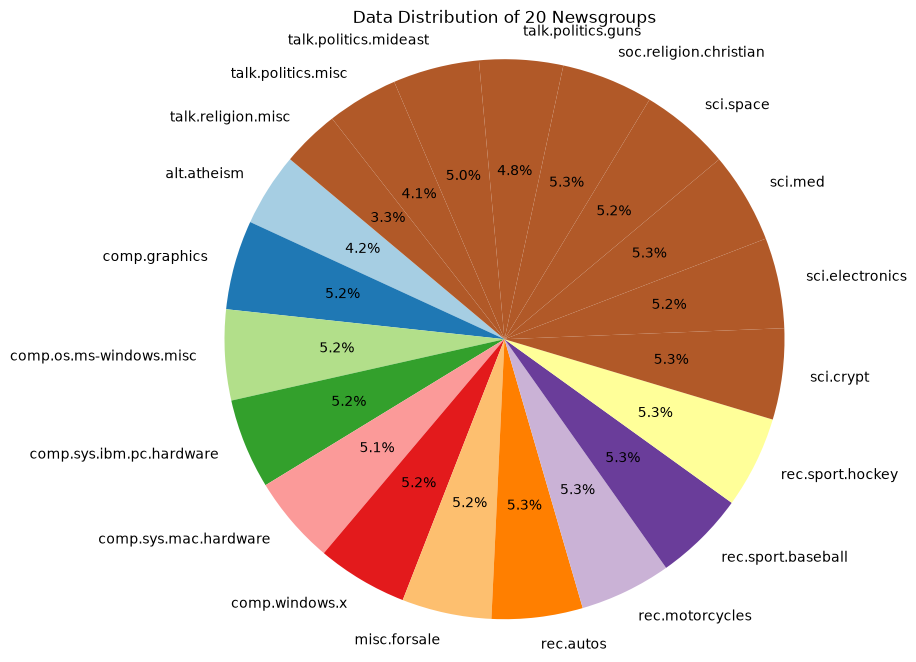

In [7]:
# Count the number of documents in each category
category_counts = dict(zip(newsgroups.target_names, [0] * len(newsgroups.target_names)))
print(category_counts)
for target in newsgroups.target:
    category_counts[newsgroups.target_names[target]] += 1

# Data to plot
labels = list(category_counts.keys())
sizes = list(category_counts.values())
colors = plt.cm.Paired(range(len(labels)))

# Plot
plt.figure(figsize=(10, 8))
plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=140)
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.title('Data Distribution of 20 Newsgroups')
plt.show()

## Load Training Set from NewsGroups Dataset

In [8]:
#Loading the training data.
mydata_train = fetch_20newsgroups(subset='train', shuffle=True, remove = ('headers', 'footers', 'quotes'))
print('Training data size:', len(mydata_train['data']))

Training data size: 11314


## Load Test Set from NewsGroup Dataset

In [9]:
#Loading the test data.
mydata_test = fetch_20newsgroups(subset='test', shuffle=True, remove = ('headers', 'footers', 'quotes'))
print('Test data size:', len(mydata_test['data']))

Test data size: 7532


In [10]:
# you can store the data in dataframe for easier processing

mydata_train_df = pd.DataFrame({'data': mydata_train.data, 
                                'target': mydata_train.target}).dropna()

mydata_train_df.head(), print(len(mydata_train_df))

11314


(                                                data  target
 0  I was wondering if anyone out there could enli...       7
 1  A fair number of brave souls who upgraded thei...       4
 2  well folks, my mac plus finally gave up the gh...       4
 3  \nDo you have Weitek's address/phone number?  ...       1
 4  From article <C5owCB.n3p@world.std.com>, by to...      14,
 None)

In [11]:
mydata_train_df = mydata_train_df.dropna()
len(mydata_train_df)

11314

In [12]:
# Preparing test data accordingly
mydata_test_df = pd.DataFrame({'data': mydata_test.data,
                                'target': mydata_test.target}).dropna()
mydata_test_df.head(), print(len(mydata_test_df))

7532


(                                                data  target
 0  I am a little confused on all of the models of...       7
 1  I'm not familiar at all with the format of the...       5
 2                                \nIn a word, yes.\n       0
 3  \nThey were attacking the Iraqis to drive them...      17
 4  \nI've just spent two solid months arguing tha...      19,
 None)

In [13]:
## we will make a function to preprocess one data point, and then we can apply it to all of the data

## Basic preprcessing function

import re
def preprocess(text):
    text = text.lower()
    text = re.sub(r'\d+', '', text) ## remove the numbers 
    text = re.sub(r'[^\w\s]', '', text)
    text = re.sub(r'_', '', text)
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [14]:
## Stemmer function
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer
nltk.download('punkt_tab')

stemmer = PorterStemmer()

def stem_text(text):
    tokens = word_tokenize(text)
    tokens = [stemmer.stem(word) for word in tokens]
    return ' '.join(tokens)

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\dbhagria\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [15]:
## testing the stem text function
tokens = stem_text(mydata_test_df['data'][0])
tokens

'i am a littl confus on all of the model of the 88-89 bonnevil . i have heard of the le se lse sse ssei . could someon tell me the differ are far as featur or perform . i am also curiou to know what the book valu is for prefer the 89 model . and how much less than book valu can you usual get them for . in other word how much are they in demand thi time of year . i have heard that the mid-spr earli summer is the best time to buy .'

In [16]:
## Lemmatization function and removing stop words

from nltk import WordNetLemmatizer
from nltk.corpus import stopwords

nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('stopwords')

lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))
def lemmatize_text_and_remove_stop_words(text):
    tokens = word_tokenize(text)

    ## remove stop words 
    tokens = [word for word in tokens if word not in stop_words]
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    return ' '.join(tokens)

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\dbhagria\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\dbhagria\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\dbhagria\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [17]:
# <<<<    Add code  here    >>>>
# Suggestions: Text preprocessing steps - remove numbers, captial letters and punctuation
# apply preprocessing to both training and test sets
# lets assume you store preprocessed data in: 
# mydata_train_df['preproc']
# mydata_test_df['preproc']


# We will only use Lemmatization

mydata_train_df['preproc'] = mydata_train_df['data'].apply(preprocess).apply(lemmatize_text_and_remove_stop_words)
mydata_test_df['preproc'] = mydata_test_df['data'].apply(preprocess).apply(lemmatize_text_and_remove_stop_words)



## TF-IDF Vectorization
Implement TF-IDF here. You can use sklearn.

In [21]:
# <<<<    Add code  here    >>>>
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()

X_train = tfidf.fit_transform(mydata_train_df['preproc'])
X_test = tfidf.transform(mydata_test_df['preproc'])

y_train = mydata_train_df['target']
y_test = mydata_test_df['target']


In [19]:
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(11314, 85561) (11314,) (7532, 85561) (7532,)


## Logistic Regression Classifier
Implement LR classifier here. You can use sklearn.

In [22]:
# <<<<    Add code  here    >>>>
from sklearn.linear_model import LogisticRegression

LR_Classifier = LogisticRegression(max_iter=1000)
LR_Classifier.fit(X_train, y_train)

# lets assume your classifier is called 'LR_Classifier'
print("Accuracy: " + str(LR_Classifier.score(X_test, y_test)))


Accuracy: 0.6784386617100372


## Model Evaluation

## Confusion Matrix
A confusion matrix is a table used in machine learning for evaluating the performance of a classification algorithm. It is particularly useful for understanding how well a model is performing in terms of correctly and incorrectly classifying instances across different categories. 

In multi-class classification scenarios, the confusion matrix helps identify specific classes that may be more challenging for the model to predict and how classes are confused with one another. Each row of the matrix represents the instances in an actual class, while each column represents the instances in a predicted class. 

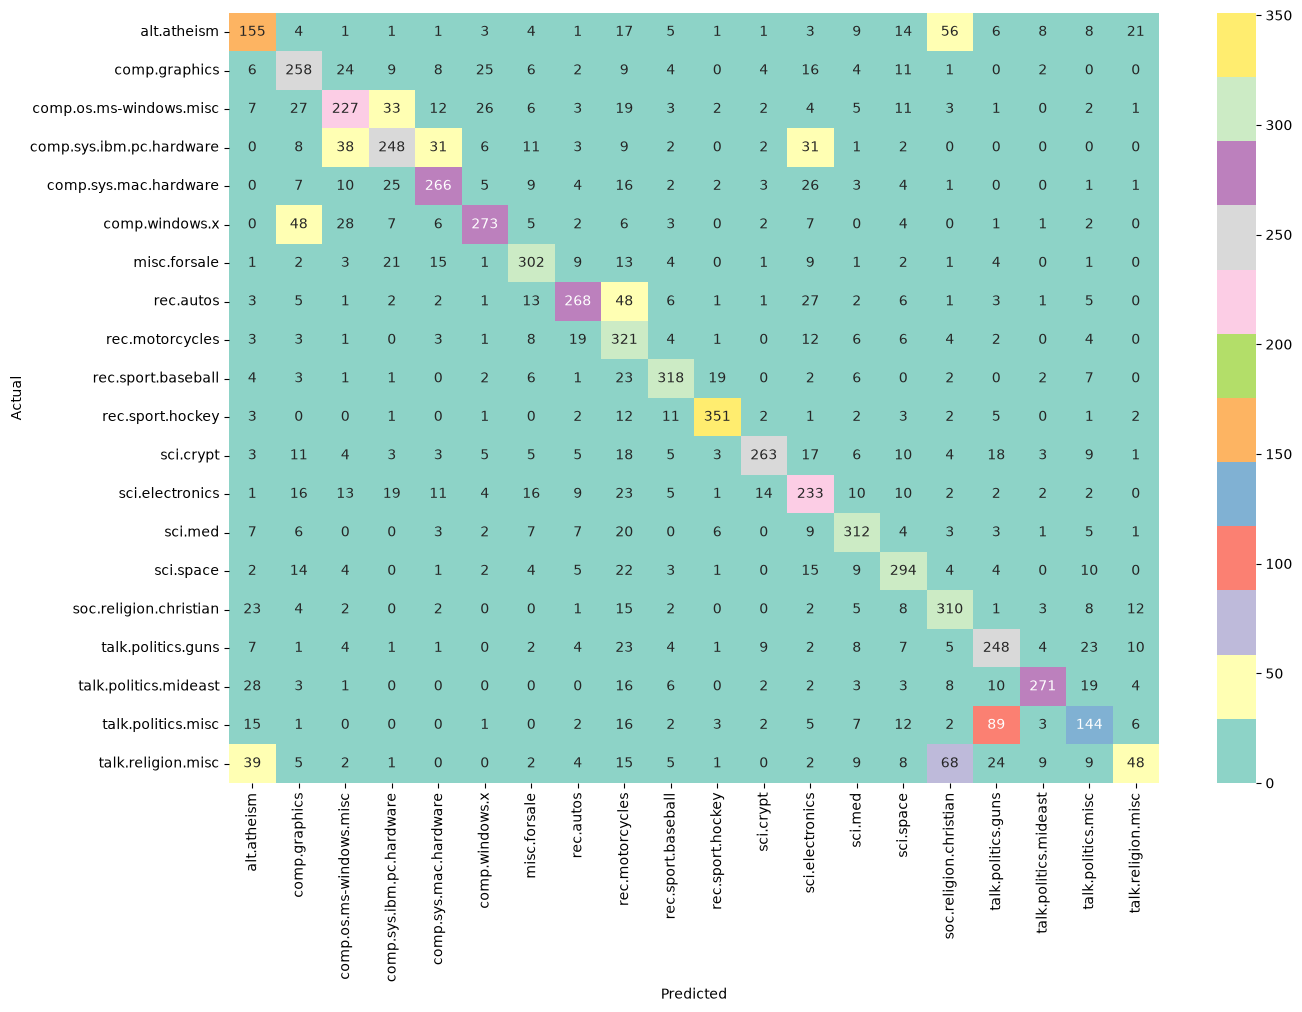

In [23]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay
import seaborn as sns

# store predictions on test set in y_pred
y_pred = LR_Classifier.predict(X_test)

# calculate confusion matrix using built-in functionality in sklearn
conf_mat = confusion_matrix(y_test, y_pred)

# Plot confusion_matrix
fig, ax = plt.subplots(figsize=(15, 10))

# remember labels = list(category_counts.keys())
sns.heatmap(conf_mat, annot=True, cmap = "Set3", fmt ="d", xticklabels=labels, yticklabels=labels)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

In [24]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision (weighted):", precision_score(y_test, y_pred, average='weighted'))
print("Recall (weighted):", recall_score(y_test, y_pred, average='weighted'))
print("F1-score (weighted):", f1_score(y_test, y_pred, average='weighted'))

Accuracy: 0.6784386617100372
Precision (weighted): 0.6859996804936037
Recall (weighted): 0.6784386617100372
F1-score (weighted): 0.6762533835382278


In [26]:
print("Classification Report:" , classification_report(y_test, y_pred))

Classification Report:               precision    recall  f1-score   support

           0       0.50      0.49      0.50       319
           1       0.61      0.66      0.63       389
           2       0.62      0.58      0.60       394
           3       0.67      0.63      0.65       392
           4       0.73      0.69      0.71       385
           5       0.76      0.69      0.73       395
           6       0.74      0.77      0.76       390
           7       0.76      0.68      0.72       396
           8       0.49      0.81      0.61       398
           9       0.81      0.80      0.80       397
          10       0.89      0.88      0.89       399
          11       0.85      0.66      0.75       396
          12       0.55      0.59      0.57       393
          13       0.76      0.79      0.78       396
          14       0.70      0.75      0.72       394
          15       0.65      0.78      0.71       398
          16       0.59      0.68      0.63       364
    

## Discussion

### Methodology
I used the 20 Newsgroups dataset (11,314 training and 7,532 test documents), removing headers, footers, and quotes so the model learns from the actual text rather than metadata. Preprocessing included lowercasing, removing numbers and punctuation, tokenizing, removing stop words, and lemmatizing with NLTK. I chose lemmatization over stemming because it keeps real words. The text was converted to TF-IDF features (85,561 terms) and used to train a logistic regression classifier.

### Resultsm
The model achieved **67.8% accuracy**, with weighted precision of 0.686, recall of 0.678, and F1-score of 0.676. The metrics are close to each other, so the model isn't strongly biased toward any class. This accuracy is reasonable given that removing headers and quotes leaves many posts short or nearly empty.

### Error Analysis
Most errors happen between related categories. The computer groups (PC hardware, Mac hardware, Windows, graphics) are often confused because they share vocabulary like drivers, memory, and monitors. The religion groups (alt.atheism, soc.religion.christian, talk.religion.misc) and the politics groups also overlap heavily. Categories with distinctive vocabulary, such as hockey, cryptography, and Middle East politics, perform much better. Other causes of errors include very short documents and the fact that TF-IDF ignores word order and context.

### Possible Improvements
- Add bigrams and use `sublinear_tf`, `min_df`, and `max_df` in the vectorizer
- Tune the regularization parameter `C` with cross-validation
- Compare with Linear SVM or Naive Bayes
- Remove empty documents before training
- Try a contextual model like BERT to better separate overlapping categories